# Word Embeddings in NLP: Frequency-Based vs Prediction-Based

This notebook implements the main word-embedding families **from scratch** (NumPy + scikit-learn), so you can see exactly what happens inside them.

| Family | Methods covered here |
|---|---|
| **Frequency-based** | One-Hot, Bag of Words (Count), TF-IDF, Co-occurrence matrix, PPMI, SVD / LSA |
| **Prediction-based** | Word2Vec Skip-gram with Negative Sampling, Word2Vec CBOW, (GloVe as the hybrid) |

No internet or paid API is needed. A small synthetic corpus with clear semantic groups (animals, fruits, vehicles, royalty) lets you *see* embeddings cluster.

See `theory.md` for the explanations and math behind each method.

## 1. Setup and corpus

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

rng = np.random.default_rng(42)
np.set_printoptions(precision=3, suppress=True)

# ---- Synthetic corpus: 4 semantic groups sharing sentence templates ----
groups = {
    "animals":  ["cat", "dog", "horse", "cow", "lion", "tiger"],
    "fruits":   ["apple", "banana", "mango", "orange", "grape"],
    "vehicles": ["car", "bus", "truck", "train", "bike"],
    "royalty":  ["king", "queen", "prince", "princess"],
}
templates = {
    "animals":  ["the {w} runs in the field", "a {w} eats food and sleeps",
                 "the {w} is a wild animal", "my {w} likes to play outside"],
    "fruits":   ["i eat a sweet {w} for breakfast", "the {w} is a fresh fruit",
                 "she bought a ripe {w} from the market", "the {w} tastes sweet and juicy"],
    "vehicles": ["he drives the {w} on the road", "the {w} is a fast vehicle",
                 "the {w} needs fuel to run", "we travel by {w} to the city"],
    "royalty":  ["the {w} rules the kingdom", "the {w} lives in the royal palace",
                 "the people respect the {w} of the kingdom", "the {w} wears a golden crown"],
}

corpus = []
for _ in range(800):
    g = rng.choice(list(groups))
    w = rng.choice(groups[g])
    t = rng.choice(templates[g])
    corpus.append(t.format(w=w))

print(len(corpus), "sentences")
for s in corpus[:5]:
    print(" -", s)

800 sentences
 - the lion is a wild animal
 - the mango tastes sweet and juicy
 - the lion runs in the field
 - my cow likes to play outside
 - the train needs fuel to run


In [2]:
def tokenize(s):
    return re.findall(r"[a-z]+", s.lower())

tokens = [tokenize(s) for s in corpus]
word_counts = Counter(w for sent in tokens for w in sent)
vocab = sorted(word_counts)
w2i = {w: i for i, w in enumerate(vocab)}
i2w = {i: w for w, i in w2i.items()}
V = len(vocab)
print("Vocabulary size:", V)
print("Most common:", word_counts.most_common(8))

Vocabulary size: 75
Most common: [('the', 955), ('a', 357), ('is', 147), ('to', 142), ('in', 112), ('kingdom', 100), ('sweet', 97), ('and', 96)]


## 2. Helper functions
Cosine similarity, nearest neighbours, and a 2-D PCA plot are reused for every embedding.

In [3]:
def normalize(M):
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-12)

def nearest(word, E, k=5):
    """Top-k most cosine-similar words to `word` in embedding matrix E (V x d)."""
    En = normalize(E)
    sims = En @ En[w2i[word]]
    order = np.argsort(-sims)
    return [(i2w[i], round(float(sims[i]), 3)) for i in order if i != w2i[word]][:k]

def plot_embeddings(E, title, words=None):
    """Project to 2-D with PCA (via SVD) and colour by semantic group."""
    X = E - E.mean(axis=0)
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    X2 = X @ Vt[:2].T
    colors = {"animals": "tab:red", "fruits": "tab:orange", "vehicles": "tab:blue", "royalty": "tab:purple"}
    plt.figure(figsize=(7, 5))
    for g, ws in groups.items():
        for w in ws:
            x, y = X2[w2i[w]]
            plt.scatter(x, y, c=colors[g])
            plt.annotate(w, (x, y), fontsize=9, xytext=(3, 3), textcoords="offset points")
    for g, c in colors.items():
        plt.scatter([], [], c=c, label=g)
    plt.legend(); plt.title(title); plt.grid(alpha=.3); plt.show()

def group_separation(E):
    """Mean cosine similarity within groups minus across groups (higher = better structure)."""
    En = normalize(E)
    within, across = [], []
    names = [(g, w) for g, ws in groups.items() for w in ws]
    for a, (ga, wa) in enumerate(names):
        for b, (gb, wb) in enumerate(names):
            if a < b:
                s = float(En[w2i[wa]] @ En[w2i[wb]])
                (within if ga == gb else across).append(s)
    return np.mean(within) - np.mean(across)

# Part A: Frequency-Based Embeddings
These methods build vectors from **counts**: how often words appear, in which documents, or next to which words.

## A1. One-Hot Encoding
Each word is a vector of length `V` with a single `1`. No notion of similarity: every pair of words is orthogonal.

In [4]:
one_hot = np.eye(V)
print("one-hot('king'):", one_hot[w2i['king']].astype(int))
print("cos(king, queen) =", float(one_hot[w2i['king']] @ one_hot[w2i['queen']]))
print("cos(king, king)  =", float(one_hot[w2i['king']] @ one_hot[w2i['king']]))
print("Separation score:", round(group_separation(one_hot), 3), "(no structure)")

one-hot('king'): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0]
cos(king, queen) = 0.0
cos(king, king)  = 1.0
Separation score: 0.0 (no structure)


## A2. Bag of Words (Count Vectorizer)
This one embeds **documents**, not words: each sentence becomes a vector of word counts. It's the simplest count-based representation, and the *columns* of this matrix can be read as crude word vectors (a word is described by the documents it appears in).

In [5]:
cv = CountVectorizer(vocabulary=vocab, token_pattern=r"[a-z]+")   # keep 1-letter words like "a"
X_bow = cv.fit_transform(corpus)          # (n_docs x V) sparse
print("BoW shape:", X_bow.shape)
print("Sentence:", corpus[0])
row = X_bow[0].toarray()[0]
print({cv.get_feature_names_out()[i]: int(c) for i, c in enumerate(row) if c})

# Word vectors = columns of the term-document matrix
bow_word_vecs = X_bow.T.toarray().astype(float)         # (V x n_docs), rows follow `vocab` order
print("Word-vector dimensionality equals number of documents:", bow_word_vecs.shape[1])
print("Separation score:", round(group_separation(bow_word_vecs), 3))

BoW shape: (800, 75)
Sentence: the lion is a wild animal
{'a': 1, 'animal': 1, 'is': 1, 'lion': 1, 'the': 1, 'wild': 1}
Word-vector dimensionality equals number of documents: 800
Separation score: 0.0


## A3. TF-IDF
Weights each count by how **rare** the word is across documents:

$$\text{tfidf}(t,d) = \text{tf}(t,d)\cdot \log\frac{N}{1+\text{df}(t)}$$

Words like "the" get down-weighted; distinctive words get boosted. First by hand, then verified with scikit-learn.

In [6]:
# --- manual TF-IDF ---
N = len(corpus)
tf = np.zeros((N, V))
for d, sent in enumerate(tokens):
    for w in sent:
        tf[d, w2i[w]] += 1
df = (tf > 0).sum(axis=0)
idf = np.log((1 + N) / (1 + df)) + 1          # smooth idf (same as sklearn)
tfidf_manual = tf * idf
tfidf_manual = tfidf_manual / np.linalg.norm(tfidf_manual, axis=1, keepdims=True)  # L2 norm

# --- scikit-learn ---
tv = TfidfVectorizer(vocabulary=vocab, token_pattern=r"[a-z]+")
tfidf_sk = tv.fit_transform(corpus).toarray()
print("Manual matches sklearn:", np.allclose(tfidf_manual, tfidf_sk))

print("\nIDF values (rare words get higher weight):")
for w in ["the", "is", "a", "king", "mango", "palace"]:
    print(f"  {w:8s} idf = {idf[w2i[w]]:.3f}")

tfidf_word_vecs = tfidf_sk.T                    # (V x N)
print("\nSeparation score:", round(group_separation(tfidf_word_vecs), 3))

Manual matches sklearn: True

IDF values (rare words get higher weight):
  the      idf = 1.192
  is       idf = 2.689
  a        idf = 1.805
  king     idf = 3.608
  mango    idf = 3.902
  palace   idf = 3.543

Separation score: 0.0


## A4. Word-Word Co-occurrence Matrix
Count how often word *j* appears within a window of `±w` words of word *i*. This captures the **distributional hypothesis**: *words in similar contexts have similar meanings*.

In [7]:
def cooccurrence_matrix(tokens, window=2, distance_weight=False):
    C = np.zeros((V, V))
    for sent in tokens:
        for i, w in enumerate(sent):
            for j in range(max(0, i - window), min(len(sent), i + window + 1)):
                if i != j:
                    C[w2i[w], w2i[sent[j]]] += (1.0 / abs(i - j)) if distance_weight else 1.0
    return C

C = cooccurrence_matrix(tokens, window=2)
print("Co-occurrence matrix:", C.shape, "| non-zero entries:", int((C > 0).sum()), "of", V * V)
print("\nContexts of 'king':")
print(sorted([(i2w[j], int(C[w2i['king'], j])) for j in range(V) if C[w2i['king'], j] > 0],
             key=lambda x: -x[1])[:8])
print("\nSeparation score (raw counts):", round(group_separation(C), 3))
print("Nearest to 'king':", nearest("king", C))

Co-occurrence matrix: (75, 75) | non-zero entries: 558 of 5625

Contexts of 'king':
[('the', 85), ('in', 21), ('lives', 21), ('rules', 16), ('of', 11), ('respect', 11), ('a', 10), ('wears', 10)]

Separation score (raw counts): 0.338
Nearest to 'king': [('princess', 0.987), ('queen', 0.986), ('prince', 0.979), ('runs', 0.893), ('lives', 0.887)]


## A5. PPMI: fixing raw counts
Raw counts are dominated by frequent words ("the"). **Pointwise Mutual Information** asks: *do these words co-occur more than chance?*

$$\text{PMI}(w,c)=\log\frac{P(w,c)}{P(w)P(c)},\qquad \text{PPMI}=\max(\text{PMI},0)$$

In [8]:
def ppmi(C, alpha=0.75):
    total = C.sum()
    pw = C.sum(axis=1, keepdims=True) / total
    pc = (C.sum(axis=0, keepdims=True) ** alpha)
    pc = pc / pc.sum()                      # context smoothing (alpha=0.75)
    pwc = C / total
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log(pwc / (pw * pc))
    pmi[~np.isfinite(pmi)] = 0
    return np.maximum(pmi, 0)

P = ppmi(C)
print("Separation score (PPMI):", round(group_separation(P), 3), "vs raw:", round(group_separation(C), 3))
print("Nearest to 'king' (PPMI):", nearest("king", P))

Separation score (PPMI): 0.841 vs raw: 0.338
Nearest to 'king' (PPMI): [('princess', 0.973), ('queen', 0.969), ('prince', 0.946), ('kingdom', 0.65), ('people', 0.509)]


## A6. Dimensionality Reduction: SVD / LSA
The PPMI matrix is `V x V`, sparse and high-dimensional. **Truncated SVD** compresses it into short, **dense** vectors:

$$M \approx U_k \Sigma_k V_k^\top \;\Rightarrow\; \text{embeddings}=U_k\Sigma_k^{1/2}$$

This is the classic *Latent Semantic Analysis* recipe: count, reweight, factorise.

Dense embedding shape: (75, 10)
Top singular values: [15.218 12.926 12.035 10.796  9.941  9.376  8.793  8.474]
Separation score (SVD of PPMI): 0.933
  king   -> [('princess', 0.999), ('queen', 0.995), ('kingdom', 0.994), ('prince', 0.987)]
  apple  -> [('orange', 0.999), ('mango', 0.998), ('banana', 0.996), ('grape', 0.995)]
  car    -> [('truck', 0.997), ('bus', 0.996), ('bike', 0.992), ('train', 0.99)]
  dog    -> [('horse', 0.999), ('cat', 0.998), ('tiger', 0.987), ('cow', 0.983)]


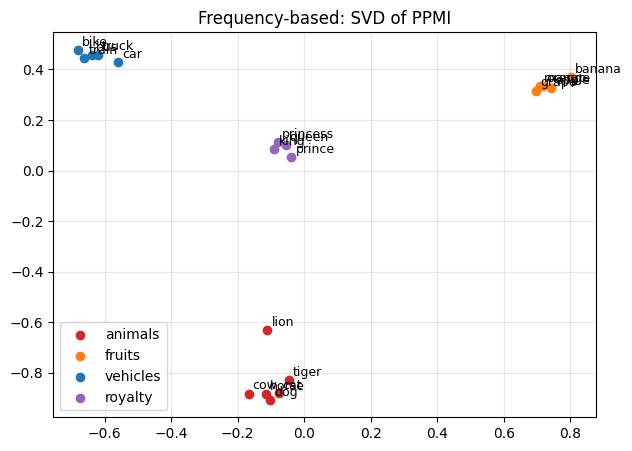

In [9]:
def svd_embeddings(M, k=10):
    U, S, Vt = np.linalg.svd(M, full_matrices=False)
    return U[:, :k] * np.sqrt(S[:k]), S

E_svd, S = svd_embeddings(P, k=10)
print("Dense embedding shape:", E_svd.shape)
print("Top singular values:", S[:8])
print("Separation score (SVD of PPMI):", round(group_separation(E_svd), 3))
for w in ["king", "apple", "car", "dog"]:
    print(f"  {w:6s} ->", nearest(w, E_svd, k=4))
plot_embeddings(E_svd, "Frequency-based: SVD of PPMI")

# Part B: Prediction-Based Embeddings
Instead of counting then factorising, we **train a small neural model** to predict words from context (or vice versa). The embeddings are the learned weights.

## B1. Training pairs
For a window of size `w`, every (center, context) pair becomes a training example.
- **Skip-gram:** center → predict each context word
- **CBOW:** all context words → predict the center word

In [10]:
def skipgram_pairs(tokens, window=2):
    pairs = []
    for sent in tokens:
        ids = [w2i[w] for w in sent]
        for i, c in enumerate(ids):
            for j in range(max(0, i - window), min(len(ids), i + window + 1)):
                if i != j:
                    pairs.append((c, ids[j]))
    return np.array(pairs)

pairs = skipgram_pairs(tokens, window=2)
print("Training pairs:", pairs.shape[0])
print("Examples:", [(i2w[a], i2w[b]) for a, b in pairs[:6]])

Training pairs: 15804
Examples: [('the', 'lion'), ('the', 'is'), ('lion', 'the'), ('lion', 'is'), ('lion', 'a'), ('is', 'the')]


## B2. Word2Vec: Skip-gram with Negative Sampling (SGNS)
Full softmax over `V` words is expensive, so we turn it into **binary classification**: is this (center, context) pair real, or a random "negative" pair?

$$\mathcal{L}=-\log\sigma(u_o^\top v_c)-\sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_c)$$

Negatives are drawn from the unigram distribution raised to the power 0.75. Gradients are derived by hand below.

In [11]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -30, 30)))

def train_sgns(pairs, dim=16, epochs=10, lr=0.025, neg=5, seed=0):
    r = np.random.default_rng(seed)
    W_in  = (r.random((V, dim)) - 0.5) / dim      # center vectors  (the embeddings)
    W_out = np.zeros((V, dim))                    # context vectors
    freq = np.array([word_counts[i2w[i]] for i in range(V)], dtype=float) ** 0.75
    neg_dist = freq / freq.sum()
    losses = []
    for ep in range(epochs):
        r.shuffle(pairs)
        total = 0.0
        negs_all = r.choice(V, size=(len(pairs), neg), p=neg_dist)
        for (c, o), negs in zip(pairs, negs_all):
            v = W_in[c].copy()
            targets = np.concatenate(([o], negs))
            labels = np.array([1.0] + [0.0] * neg)
            u = W_out[targets]                    # (1+neg, dim)
            p = sigmoid(u @ v)
            total += -np.log(p[0] + 1e-10) - np.log(1 - p[1:] + 1e-10).sum()
            g = p - labels                        # dL/dscore
            W_in[c] -= lr * (g @ u)
            np.add.at(W_out, targets, -lr * np.outer(g, v))
        losses.append(total / len(pairs))
        print(f"epoch {ep+1}/{epochs}  loss = {losses[-1]:.4f}")
    return W_in, W_out, losses

W_sg, W_sg_out, sg_losses = train_sgns(pairs.copy(), dim=16, epochs=10)
E_sg = W_sg + W_sg_out        # common trick: sum input and output vectors

epoch 1/10  loss = 3.0379
epoch 2/10  loss = 2.0960
epoch 3/10  loss = 1.7415
epoch 4/10  loss = 1.5527
epoch 5/10  loss = 1.4768
epoch 6/10  loss = 1.4498
epoch 7/10  loss = 1.4401
epoch 8/10  loss = 1.4330
epoch 9/10  loss = 1.4258
epoch 10/10  loss = 1.4279


Separation score (Skip-gram): 1.246
  king   -> [('princess', 0.982), ('queen', 0.974), ('prince', 0.97), ('lives', 0.964)]
  apple  -> [('grape', 0.97), ('orange', 0.963), ('banana', 0.962), ('mango', 0.957)]
  car    -> [('bike', 0.973), ('truck', 0.967), ('train', 0.965), ('bus', 0.957)]
  dog    -> [('horse', 0.994), ('cat', 0.986), ('cow', 0.966), ('lion', 0.94)]


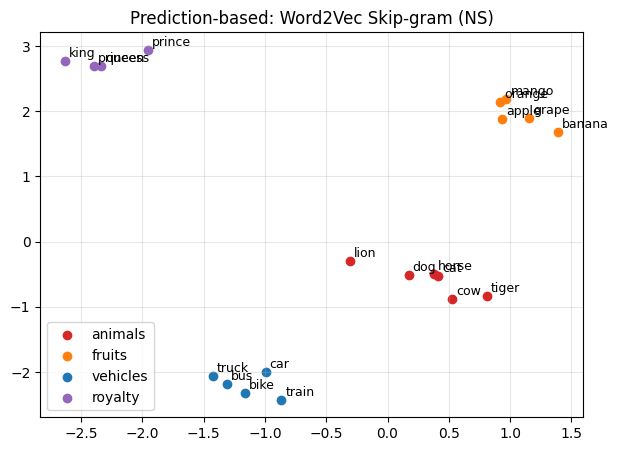

In [12]:
print("Separation score (Skip-gram):", round(group_separation(E_sg), 3))
for w in ["king", "apple", "car", "dog"]:
    print(f"  {w:6s} ->", nearest(w, E_sg, k=4))
plot_embeddings(E_sg, "Prediction-based: Word2Vec Skip-gram (NS)")

## B3. Word2Vec: CBOW
CBOW **averages** the context vectors and predicts the centre word. It's faster and smooths over rare words. Here it uses negative sampling as well.

In [13]:
def cbow_examples(tokens, window=2):
    ex = []
    for sent in tokens:
        ids = [w2i[w] for w in sent]
        for i, c in enumerate(ids):
            ctx = [ids[j] for j in range(max(0, i - window), min(len(ids), i + window + 1)) if j != i]
            if ctx:
                ex.append((ctx, c))
    return ex

def train_cbow(examples, dim=16, epochs=8, lr=0.05, neg=5, seed=0):
    r = np.random.default_rng(seed)
    W_in  = (r.random((V, dim)) - 0.5) / dim
    W_out = np.zeros((V, dim))
    freq = np.array([word_counts[i2w[i]] for i in range(V)], dtype=float) ** 0.75
    neg_dist = freq / freq.sum()
    for ep in range(epochs):
        order = r.permutation(len(examples))
        total = 0.0
        for idx in order:
            ctx, c = examples[idx]
            h = W_in[ctx].mean(axis=0)                       # averaged context
            negs = r.choice(V, size=neg, p=neg_dist)
            targets = np.concatenate(([c], negs))
            labels = np.array([1.0] + [0.0] * neg)
            u = W_out[targets]
            p = sigmoid(u @ h)
            total += -np.log(p[0] + 1e-10) - np.log(1 - p[1:] + 1e-10).sum()
            g = p - labels
            grad_h = g @ u
            np.add.at(W_out, targets, -lr * np.outer(g, h))
            np.add.at(W_in, ctx, -lr * grad_h / len(ctx))
        print(f"epoch {ep+1}/{epochs}  loss = {total/len(examples):.4f}")
    return W_in, W_out

cb_examples = cbow_examples(tokens)
W_cb, W_cb_out = train_cbow(cb_examples, dim=16, epochs=8)
E_cbow = W_cb + W_cb_out
print("Separation score (CBOW):", round(group_separation(E_cbow), 3))
for w in ["king", "apple", "car"]:
    print(f"  {w:6s} ->", nearest(w, E_cbow, k=4))

epoch 1/8  loss = 3.3082
epoch 2/8  loss = 2.2180
epoch 3/8  loss = 1.6494
epoch 4/8  loss = 1.3408
epoch 5/8  loss = 1.1138
epoch 6/8  loss = 0.9566
epoch 7/8  loss = 0.8650
epoch 8/8  loss = 0.7992
Separation score (CBOW): 1.124
  king   -> [('princess', 0.976), ('prince', 0.959), ('queen', 0.953), ('lives', 0.94)]
  apple  -> [('grape', 0.962), ('orange', 0.961), ('mango', 0.958), ('banana', 0.944)]
  car    -> [('train', 0.965), ('truck', 0.946), ('bus', 0.918), ('bike', 0.914)]


## B4. GloVe: the hybrid
GloVe is trained by *prediction-style optimisation* (gradient descent) but on **global co-occurrence counts**, a bridge between both families:

$$J=\sum_{i,j} f(X_{ij})\left(w_i^\top \tilde w_j+b_i+\tilde b_j-\log X_{ij}\right)^2,\quad f(x)=\min\!\big(1,(x/x_{max})^{0.75}\big)$$

In [14]:
def train_glove(C, dim=8, epochs=30, lr=0.05, xmax=50, seed=0):
    r = np.random.default_rng(seed)
    W  = (r.random((V, dim)) - 0.5) / dim
    Wt = (r.random((V, dim)) - 0.5) / dim
    b, bt = np.zeros(V), np.zeros(V)
    gW, gWt = np.ones((V, dim)), np.ones((V, dim))      # AdaGrad accumulators
    gb, gbt = np.ones(V), np.ones(V)
    I, J = np.nonzero(C)
    X = C[I, J]
    f = np.minimum(1.0, (X / xmax) ** 0.75)
    logX = np.log(X)
    losses = []
    for ep in range(epochs):
        diff = (W[I] * Wt[J]).sum(1) + b[I] + bt[J] - logX
        loss = (f * diff ** 2).sum() / len(X)
        losses.append(loss)
        g = f * diff
        dW  = np.zeros_like(W);  np.add.at(dW,  I, g[:, None] * Wt[J])
        dWt = np.zeros_like(Wt); np.add.at(dWt, J, g[:, None] * W[I])
        db  = np.zeros(V);       np.add.at(db,  I, g)
        dbt = np.zeros(V);       np.add.at(dbt, J, g)
        for param, grad, acc in ((W, dW, gW), (Wt, dWt, gWt), (b, db, gb), (bt, dbt, gbt)):
            acc += grad ** 2
            param -= lr * grad / np.sqrt(acc)
        if (ep + 1) % 10 == 0:
            print(f"epoch {ep+1}/{epochs}  loss = {loss:.4f}")
    E = W + Wt
    return E - E.mean(axis=0), losses     # mean-centre: removes the shared frequency direction

E_glove, gl_losses = train_glove(cooccurrence_matrix(tokens, 2, distance_weight=True), dim=8, epochs=30)
print("Separation score (GloVe):", round(group_separation(E_glove), 3))
for w in ["king", "apple", "car"]:
    print(f"  {w:6s} ->", nearest(w, E_glove, k=4))

epoch 10/30  loss = 3.5448
epoch 20/30  loss = 1.8508
epoch 30/30  loss = 0.8424
Separation score (GloVe): 0.817
  king   -> [('prince', 0.981), ('princess', 0.963), ('queen', 0.958), ('lion', 0.934)]
  apple  -> [('grape', 0.913), ('mango', 0.876), ('orange', 0.834), ('is', 0.688)]
  car    -> [('city', 0.968), ('on', 0.966), ('truck', 0.937), ('bus', 0.927)]


# Part C: Comparison

In [15]:
results = {
    "One-Hot":                 one_hot,
    "TF-IDF (term-doc)":       tfidf_word_vecs,
    "Co-occurrence (raw)":     C,
    "PPMI":                    P,
    "SVD of PPMI (LSA-style)": E_svd,
    "Word2Vec Skip-gram":      E_sg,
    "Word2Vec CBOW":           E_cbow,
    "GloVe":                   E_glove,
}
print(f"{'Method':28s} {'Dim':>6s}  {'Separation':>10s}")
print("-" * 48)
for name, E in results.items():
    print(f"{name:28s} {E.shape[1]:6d}  {group_separation(E):10.3f}")

Method                          Dim  Separation
------------------------------------------------
One-Hot                          75       0.000
TF-IDF (term-doc)               800       0.000
Co-occurrence (raw)              75       0.338
PPMI                             75       0.841
SVD of PPMI (LSA-style)          10       0.933
Word2Vec Skip-gram               16       1.246
Word2Vec CBOW                    16       1.124
GloVe                             8       0.817


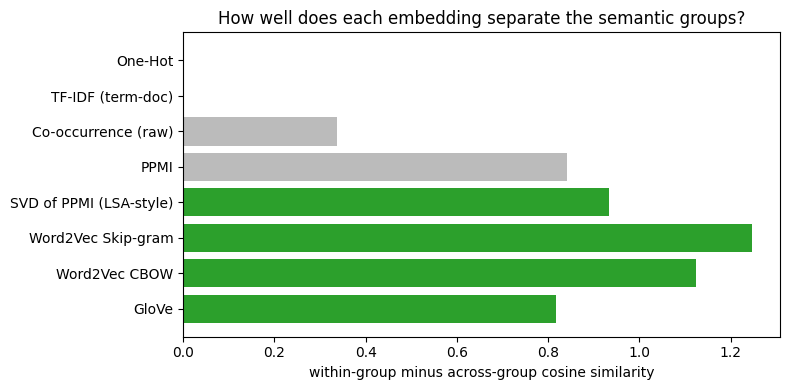

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(results)
vals = [group_separation(results[n]) for n in names]
ax.barh(names, vals, color=["#bbb"] * 4 + ["tab:green"] * 4)
ax.set_xlabel("within-group minus across-group cosine similarity")
ax.set_title("How well does each embedding separate the semantic groups?")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## Pairwise similarities
Analogies like *king - man + woman = queen* need a much larger corpus than this toy one, so instead we compare a few word pairs. Related pairs should score high and unrelated pairs low.

In [17]:
test_pairs = [("king", "queen"), ("cat", "dog"), ("apple", "banana"), ("car", "bus"),
              ("king", "apple"), ("dog", "car"), ("queen", "truck")]
methods = ["PPMI", "SVD of PPMI (LSA-style)", "Word2Vec Skip-gram", "Word2Vec CBOW", "GloVe"]
print(f"{'pair':18s}" + "".join(f"{m[:14]:>16s}" for m in methods))
for a, b in test_pairs:
    row = []
    for m in methods:
        En = normalize(results[m])
        row.append(float(En[w2i[a]] @ En[w2i[b]]))
    print(f"{a+'-'+b:18s}" + "".join(f"{v:16.3f}" for v in row))

pair                          PPMI  SVD of PPMI (L  Word2Vec Skip-   Word2Vec CBOW           GloVe
king-queen                   0.969           0.995           0.974           0.953           0.958
cat-dog                      0.994           0.998           0.986           0.965           0.964
apple-banana                 0.975           0.996           0.962           0.944           0.647
car-bus                      0.958           0.996           0.957           0.918           0.927
king-apple                   0.062           0.013          -0.158          -0.065           0.116
dog-car                      0.122           0.040          -0.283           0.066          -0.392
queen-truck                  0.117           0.083          -0.228          -0.390           0.719


# Part D (Optional): Production libraries
If you have `gensim` installed (`pip install gensim`), the same Word2Vec/FastText models take just a few lines and scale to billions of tokens.

In [18]:
try:
    from gensim.models import Word2Vec, FastText
    sg = Word2Vec(tokens, vector_size=50, window=2, min_count=1, sg=1, negative=5, epochs=50, seed=1)
    print("gensim skip-gram, nearest to 'king':", sg.wv.most_similar("king", topn=4))
    ft = FastText(tokens, vector_size=50, window=2, min_count=1, epochs=50, seed=1)
    print("FastText vector for unseen word 'kingdoms' exists:", ft.wv["kingdoms"].shape)  # subword magic
except ImportError:
    print("gensim not installed, skipping. Run: pip install gensim")

gensim skip-gram, nearest to 'king': [('princess', 0.9777926206588745), ('prince', 0.9670342803001404), ('queen', 0.962550163269043), ('kingdom', 0.8988066911697388)]
FastText vector for unseen word 'kingdoms' exists: (50,)


## Key takeaways

1. **One-hot / BoW / TF-IDF** give sparse, high-dimensional vectors with little or no semantic similarity between words.
2. **Co-occurrence + PPMI + SVD** produce dense vectors that capture meaning from *global statistics*; they are deterministic and fast.
3. **Word2Vec (Skip-gram / CBOW)** learns dense vectors by *predicting local context*, scales to huge corpora, and is online-trainable.
4. **GloVe** combines both: global counts, optimised with a prediction-style loss.
5. All of these are **static** embeddings (one vector per word). Context-dependent models like ELMo, BERT and GPT are the next step.